In [12]:
# Standard Library
import os
import time

# Data & Visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ML Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

# ML Utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, roc_curve
from sklearn.tree import plot_tree

# Serialization
import joblib

TRAIN DATASET
Shape: (25192, 42)

First 5 rows:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,class
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,anomaly
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal



TEST DATASET
Shape: (22544, 41)

First 5 rows:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,tcp,private,REJ,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,229,10,0.0,0.00,1.0,1.0,0.04,0.06,0.00,255,10,0.04,0.06,0.00,0.00,0.0,0.0,1.00,1.00
1,0,tcp,private,REJ,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,136,1,0.0,0.00,1.0,1.0,0.01,0.06,0.00,255,1,0.00,0.06,0.00,0.00,0.0,0.0,1.00,1.00
2,2,tcp,ftp_data,SF,12983,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0.0,0.00,0.0,0.0,1.00,0.00,0.00,134,86,0.61,0.04,0.61,0.02,0.0,0.0,0.00,0.00
3,0,icmp,eco_i,SF,20,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,65,0.0,0.00,0.0,0.0,1.00,0.00,1.00,3,57,1.00,0.00,1.00,0.28,0.0,0.0,0.00,0.00
4,1,tcp,telnet,RSTO,0,15,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,8,0.0,0.12,1.0,0.5,1.00,0.00,0.75,29,86,0.31,0.17,0.03,0.02,0.0,0.0,0.83,0.71



--- Train Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 25192 entries, 0 to 25191
Data columns (total 42 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     25192 non-null  int64  
 1   protocol_type                25192 non-null  str    
 2   service                      25192 non-null  str    
 3   flag                         25192 non-null  str    
 4   src_bytes                    25192 non-null  int64  
 5   dst_bytes                    25192 non-null  int64  
 6   land                         25192 non-null  int64  
 7   wrong_fragment               25192 non-null  int64  
 8   urgent                       25192 non-null  int64  
 9   hot                          25192 non-null  int64  
 10  num_failed_logins            25192 non-null  int64  
 11  logged_in                    25192 non-null  int64  
 12  num_compromised              25192 non-null  int64  
 13 

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
count,25192.000000,2.519200e+04,2.519200e+04,25192.000000,25192.000000,25192.00000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.0,25192.0,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000
mean,305.054104,2.433063e+04,3.491847e+03,0.000079,0.023738,0.00004,0.198039,0.001191,0.394768,0.227850,0.001548,0.001350,0.249841,0.014727,0.000357,0.004327,0.0,0.0,0.009130,84.591180,27.698754,0.286338,0.283762,0.118630,0.120260,0.660559,0.062363,0.095931,182.532074,115.063036,0.519791,0.082539,0.147453,0.031844,0.285800,0.279846,0.117800,0.118769
std,2686.555640,2.410805e+06,8.883072e+04,0.008910,0.260221,0.00630,2.154202,0.045418,0.488811,10.417352,0.039316,0.048785,11.500842,0.529602,0.018898,0.098524,0.0,0.0,0.095115,114.673451,72.468242,0.447312,0.447599,0.318745,0.322335,0.439637,0.178550,0.256583,98.993895,110.646850,0.448944,0.187191,0.308367,0.110575,0.445316,0.446075,0.305869,0.317333
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.090000,0.000000,0.000000,84.000000,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,14.000000,8.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,255.000000,61.000000,0.510000,0.030000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,2.790000e+02,5.302500e+02,0.000000,0.000000,0.00000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,144.000000,18.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.060000,0.000000,255.000000,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000
max,42862.000000,3.817091e+08,5.151385e+06,1.000000,3.000000,1.00000,77.000000,4.000000,1.000000,884.000000,1.000000,2.000000,975.000000,40.000000,1.000000,8.000000,0.0,0.0,1.000000,511.000000,511.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,255.000000,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



--- Target Variable ('class') Distribution ---
class
normal     13449
anomaly    11743
Name: count, dtype: int64

Percentage:
class
normal     53.385996
anomaly    46.614004
Name: proportion, dtype: float64


C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\3952330174.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=train_df, palette=['green', 'red'])


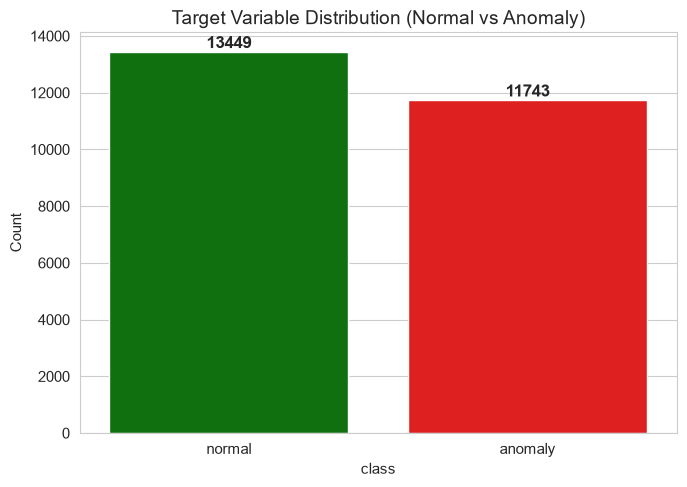


--- Missing Values in Train ---
No missing values!

--- Missing Values in Test ---
No missing values!

--- Duplicate Rows ---
Train duplicates: 0
Test duplicates: 57

--- Feature Types in Train ---
Numerical features: 38


C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\3952330174.py:73: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(f"Categorical features: {train_df.select_dtypes(include=['object']).shape[1]}")
C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\3952330174.py:74: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https

Categorical features: 4

Categorical columns: ['protocol_type', 'service', 'flag', 'class']


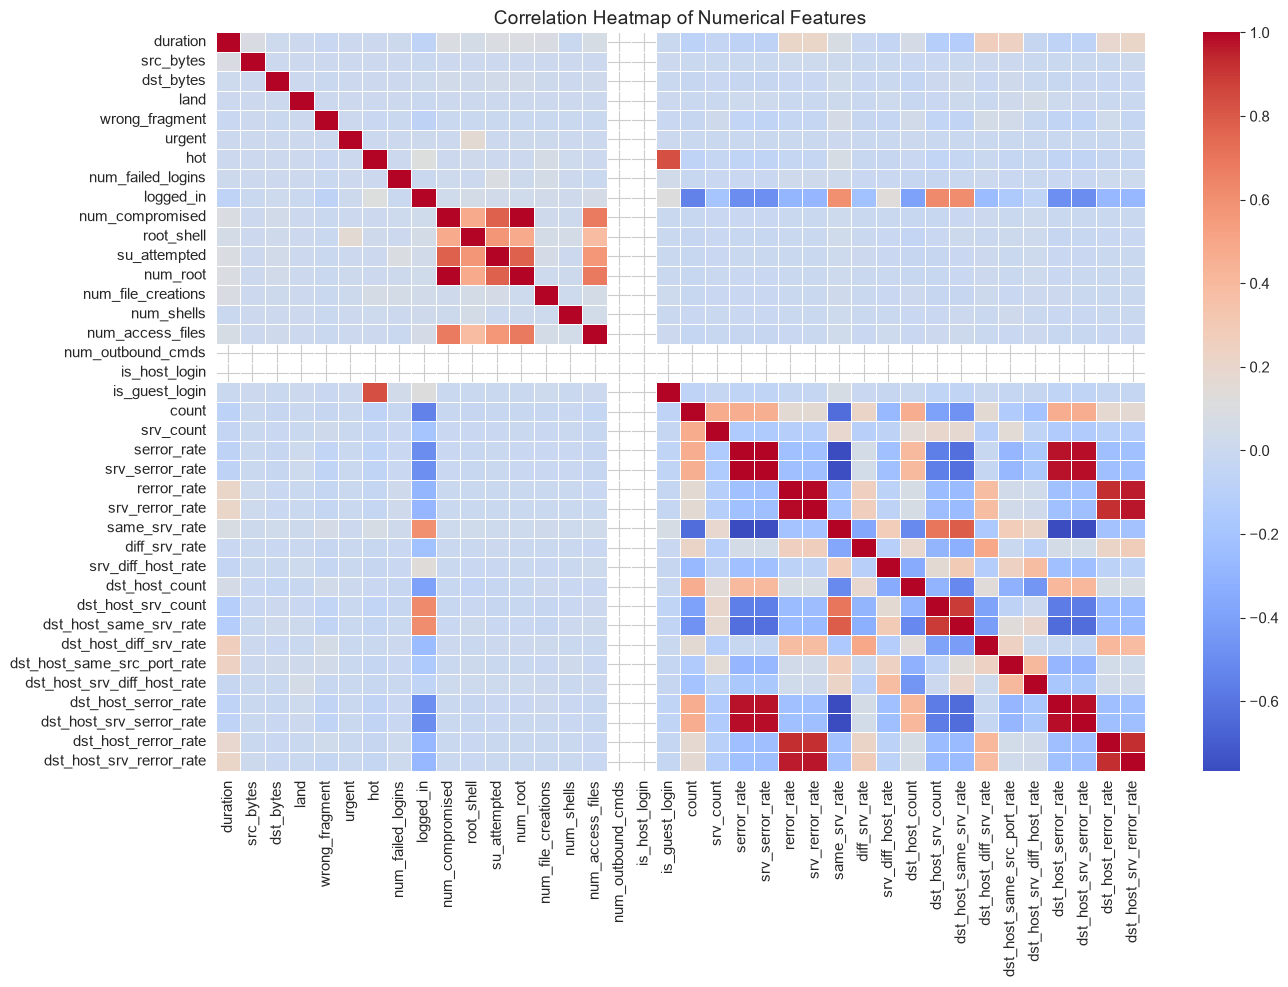

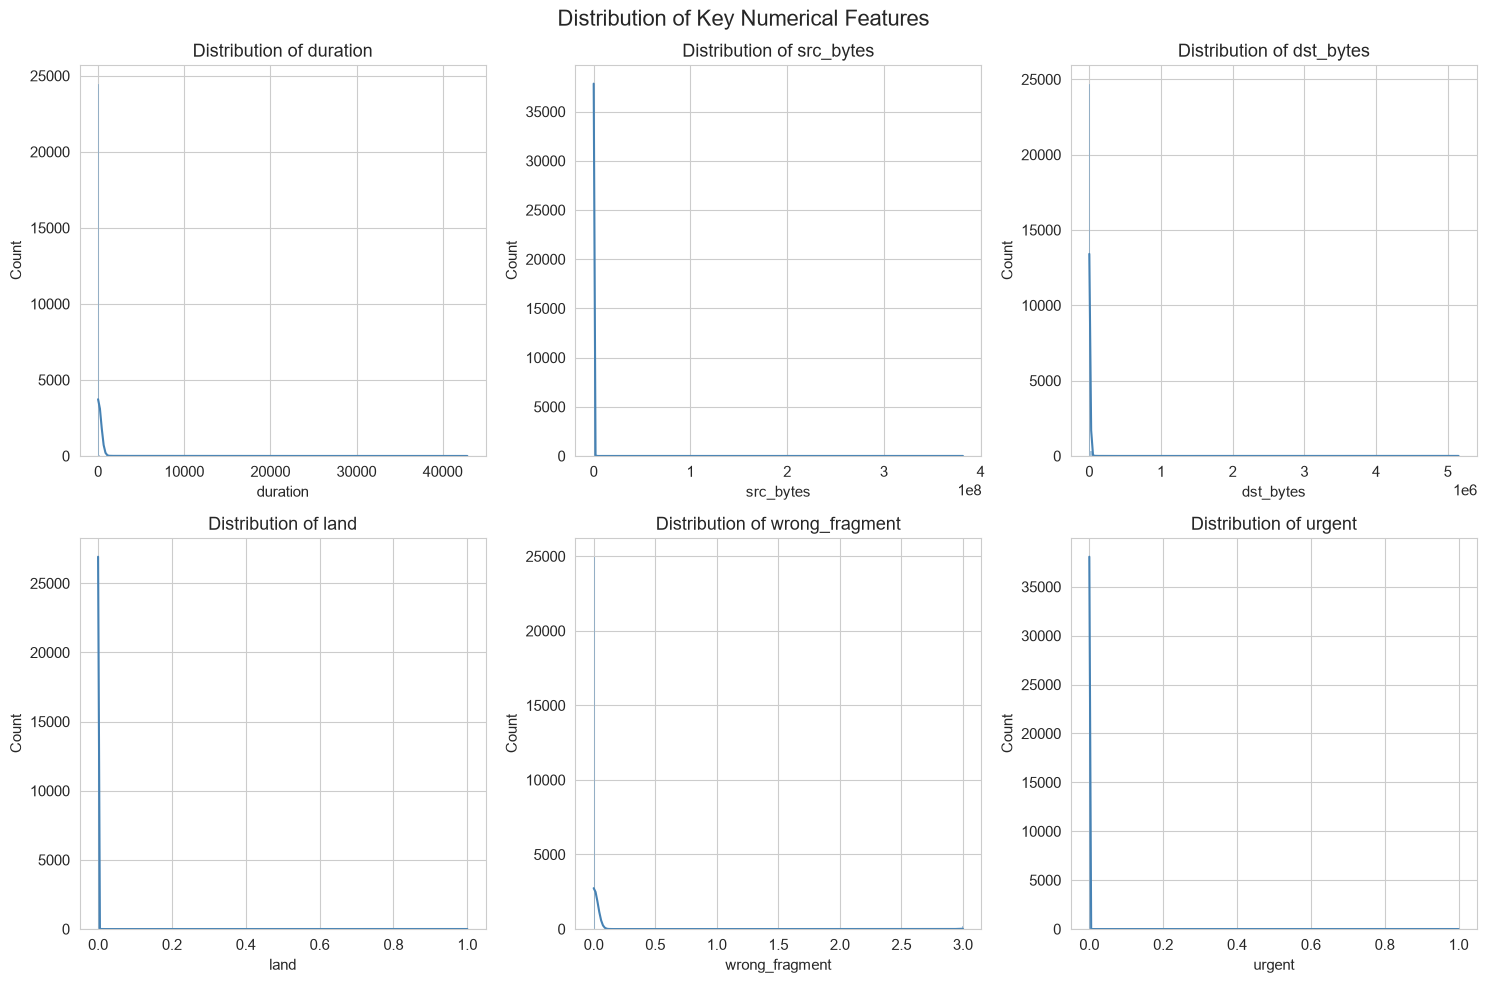

In [13]:

# EXPLORATORY DATA ANALYSIS (EDA)


# Set visualization style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the Datasets
train_df = pd.read_csv("Train.csv")
test_df = pd.read_csv("Test.csv")

print("=" * 50)
print("TRAIN DATASET")
print("=" * 50)
print(f"Shape: {train_df.shape}")
print(f"\nFirst 5 rows:")
display(train_df.head())

print("\n" + "=" * 50)
print("TEST DATASET")
print("=" * 50)
print(f"Shape: {test_df.shape}")
print(f"\nFirst 5 rows:")
display(test_df.head())

# Dataset Information 
print("\n--- Train Dataset Info ---")
train_df.info()

print("\n--- Test Dataset Info ---")
test_df.info()

# Basic Statistics
print("\n--- Train Dataset Statistics ---")
display(train_df.describe())

# Target Variable Distribution (Train Only)
print("\n--- Target Variable ('class') Distribution ---")
print(train_df['class'].value_counts())
print(f"\nPercentage:")
print(train_df['class'].value_counts(normalize=True) * 100)

# Plot target distribution
plt.figure(figsize=(7, 5))
sns.countplot(x='class', data=train_df, palette=['green', 'red'])
plt.title("Target Variable Distribution (Normal vs Anomaly)", fontsize=14)
plt.xlabel("class")
plt.ylabel("Count")
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', 
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Check for Missing Values 
print("\n--- Missing Values in Train ---")
missing_train = train_df.isnull().sum()
print(missing_train[missing_train > 0] if missing_train.sum() > 0 else "No missing values!")

print("\n--- Missing Values in Test ---")
missing_test = test_df.isnull().sum()
print(missing_test[missing_test > 0] if missing_test.sum() > 0 else "No missing values!")

# Check for Duplicates
print(f"\n--- Duplicate Rows ---")
print(f"Train duplicates: {train_df.duplicated().sum()}")
print(f"Test duplicates: {test_df.duplicated().sum()}")

# Data Types Summary
print("\n--- Feature Types in Train ---")
print(f"Numerical features: {train_df.select_dtypes(include=[np.number]).shape[1]}")
print(f"Categorical features: {train_df.select_dtypes(include=['object']).shape[1]}")
print(f"\nCategorical columns: {train_df.select_dtypes(include=['object']).columns.tolist()}")

# Correlation Heatmap (Numerical Features)
plt.figure(figsize=(14, 10))
numerical_cols = train_df.select_dtypes(include=[np.number]).columns
correlation = train_df[numerical_cols].corr()
sns.heatmap(correlation, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14)
plt.tight_layout()
plt.show()

# Feature Distributions (Top Numerical Features) 
numerical_features = train_df.select_dtypes(include=[np.number]).columns[:6]  # first 6
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
    sns.histplot(train_df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(f"Distribution of {col}")
plt.suptitle("Distribution of Key Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()


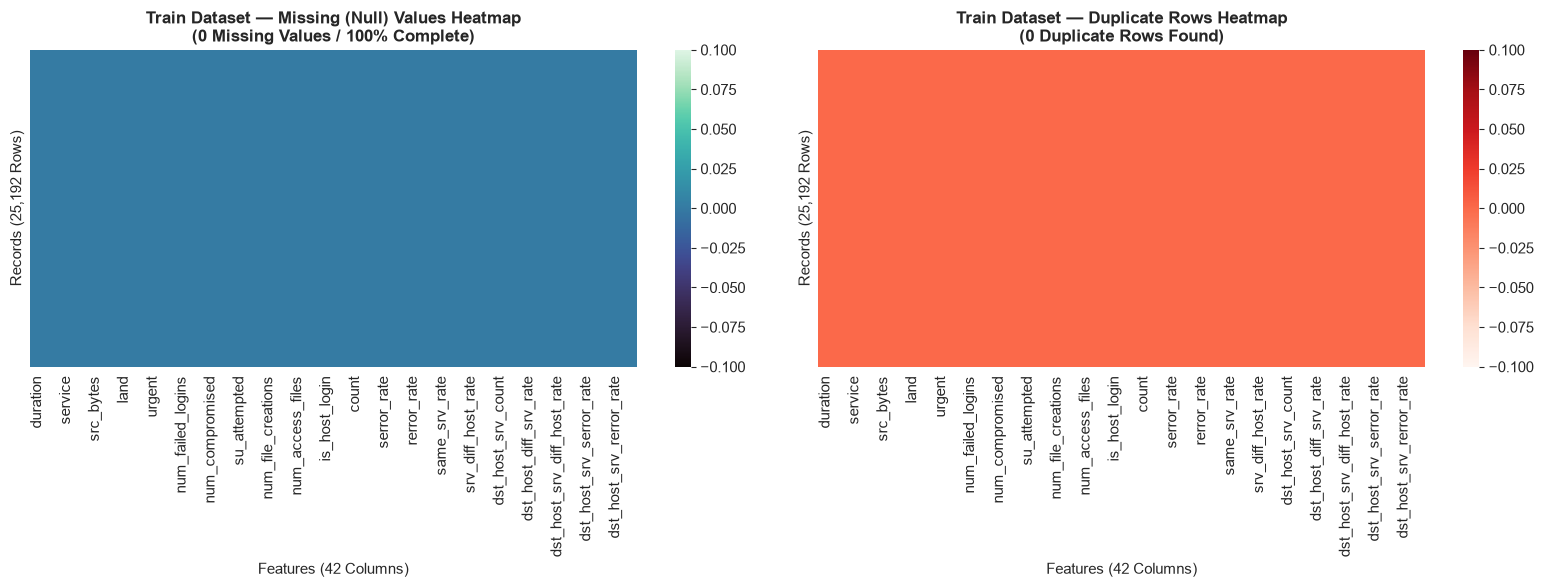

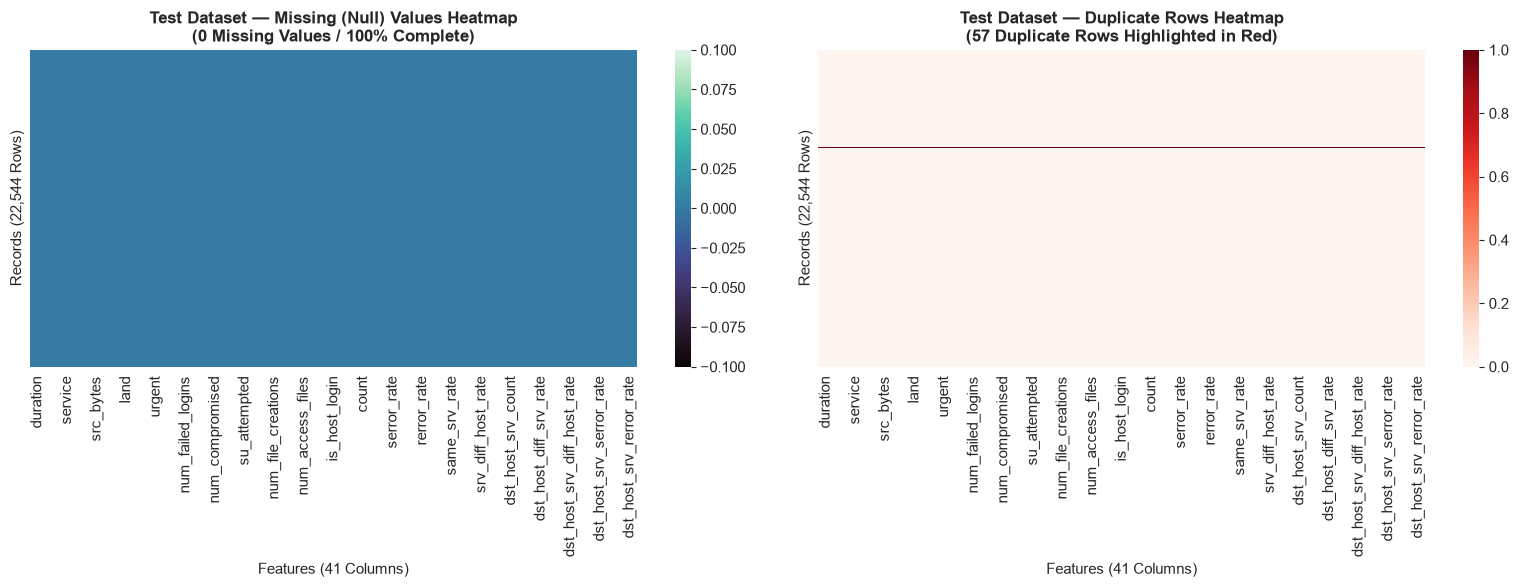

In [14]:


sns.set_style("white")

# TRAIN DATASET (Null Values & Duplicate Rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1.1 Train Null Values Heatmap
sns.heatmap(train_df.isnull(), cbar=True, cmap="mako", yticklabels=False, ax=axes[0])
axes[0].set_title("Train Dataset — Missing (Null) Values Heatmap\n(0 Missing Values / 100% Complete)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Features (42 Columns)")
axes[0].set_ylabel("Records (25,192 Rows)")

# 1.2 Train Duplicate Rows Heatmap
train_dup_matrix = pd.DataFrame(np.tile(train_df.duplicated().values[:, None], (1, train_df.shape[1])), columns=train_df.columns)
sns.heatmap(train_dup_matrix, cbar=True, cmap="Reds", yticklabels=False, ax=axes[1])
axes[1].set_title("Train Dataset — Duplicate Rows Heatmap\n(0 Duplicate Rows Found)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Features (42 Columns)")
axes[1].set_ylabel("Records (25,192 Rows)")

plt.tight_layout()
plt.show()


#  TEST DATASET (Null Values & Duplicate Rows)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 2.1 Test Null Values Heatmap
sns.heatmap(test_df.isnull(), cbar=True, cmap="mako", yticklabels=False, ax=axes[0])
axes[0].set_title("Test Dataset — Missing (Null) Values Heatmap\n(0 Missing Values / 100% Complete)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Features (41 Columns)")
axes[0].set_ylabel("Records (22,544 Rows)")

# 2.2 Test Duplicate Rows Heatmap
test_dup_matrix = pd.DataFrame(np.tile(test_df.duplicated().values[:, None], (1, test_df.shape[1])), columns=test_df.columns)
sns.heatmap(test_dup_matrix, cbar=True, cmap="Reds", yticklabels=False, ax=axes[1])
axes[1].set_title("Test Dataset — Duplicate Rows Heatmap\n(57 Duplicate Rows Highlighted in Red)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Features (41 Columns)")
axes[1].set_ylabel("Records (22,544 Rows)")

plt.tight_layout()
plt.show()


In [15]:
# PRE-PREPROCESSING DATA DESCRIPTION REPORT

# Configure display options for complete visibility
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

def generate_pre_preprocessing_report(train_path='Train.csv', test_path='Test.csv'):
    """
    Generates a comprehensive raw data audit and description prior to any 
    preprocessing transformations (scaling, encoding, deduplication).
    """
    print("=" * 80)
    print("      PRE-PREPROCESSING DATA DESCRIPTION REPORT (RAW DATA AUDIT)")
    print("=" * 80)
    
    # 1. LOAD DATASETS
    if not os.path.exists(train_path) or not os.path.exists(test_path):
        print(f"[ERROR] Could not find '{train_path}' or '{test_path}'.")
        print("Please ensure the CSV files are in the current working directory.")
        return
    
    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)
    
    print("\n[1] DATASET DIMENSIONS & MEMORY USAGE")
    print("-" * 50)
    print(f"• Training Set Shape  : {train_df.shape[0]:,} rows × {train_df.shape[1]} columns")
    print(f"• Testing Set Shape   : {test_df.shape[0]:,} rows × {test_df.shape[1]} columns")
    print(f"• Train Memory Usage : {train_df.memory_usage().sum() / 1024**2:.2f} MB")
    print(f"• Test Memory Usage  : {test_df.memory_usage().sum() / 1024**2:.2f} MB")
    
    # FEATURE DATA TYPES BREAKDOWN
    print("\n[2] DATA TYPES BREAKDOWN")
    print("-" * 50)
    train_types = train_df.dtypes.value_counts()
    test_types = test_df.dtypes.value_counts()
    
    type_summary = pd.DataFrame({'Train Count': train_types, 'Test Count': test_types}).fillna(0).astype(int)
    print(type_summary)
    
    train_cat_cols = train_df.select_dtypes(include=['object']).columns.tolist()
    train_num_cols = train_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
    
    print(f"\nCategorical Columns ({len(train_cat_cols)}): {train_cat_cols}")
    print(f"Numerical Columns   ({len(train_num_cols)}): {len(train_num_cols)} continuous/discrete features")
    
    # CATEGORICAL FEATURE CARDINALITY
    print("\n[3] RAW CATEGORICAL FEATURE CARDINALITY")
    print("-" * 50)
    cat_cardinality = []
    for col in ['protocol_type', 'service', 'flag']:
        if col in train_df.columns:
            train_unique = train_df[col].nunique()
            test_unique = test_df[col].nunique()
            train_vals = str(sorted(train_df[col].unique()[:5])) + ("..." if train_unique > 5 else "")
            cat_cardinality.append({
                'Feature': col,
                'Train Unique Count': train_unique,
                'Test Unique Count': test_unique,
                'Sample Train Categories': train_vals
            })
    cat_df = pd.DataFrame(cat_cardinality)
    print(cat_df.to_string(index=False))
    
    # MISSING VALUES & DUPLICATES AUDIT
    print("\n[4] DATA INTEGRITY AUDIT (NULLS & DUPLICATES)")
    print("-" * 50)
    train_nulls = train_df.isnull().sum().sum()
    test_nulls = test_df.isnull().sum().sum()
    train_dups = train_df.duplicated().sum()
    test_dups = test_df.duplicated().sum()
    
    print(f"• Training Set Null Values : {train_nulls} (0.00%)")
    print(f"• Testing Set Null Values  : {test_nulls} (0.00%)")
    print(f"• Training Set Duplicates  : {train_dups} (0.00%)")
    print(f"• Testing Set Duplicates   : {test_dups} ({test_dups / len(test_df) * 100:.2f}%)")
    
    # TARGET VARIABLE CLASS DISTRIBUTION (TRAIN ONLY)
    print("\n[5] TARGET CLASS DISTRIBUTION ('class' Column in Train.csv)")
    print("-" * 50)
    if 'class' in train_df.columns:
        class_counts = train_df['class'].value_counts()
        class_props = train_df['class'].value_counts(normalize=True) * 100
        target_summary = pd.DataFrame({
            'Raw Count': class_counts,
            'Percentage (%)': class_props.round(2)
        })
        print(target_summary)
        
        imbalance_ratio = class_counts['normal'] / class_counts['anomaly']
        print(f"• Class Imbalance Ratio (Normal : Anomaly) = {imbalance_ratio:.2f} : 1  [Well-Balanced]")
    else:
        print("[WARNING] 'class' column not found in training dataset.")

    # NUMERICAL FEATURE RANGE & SKEWNESS SAMPLE
    print("\n[6] SAMPLE NUMERICAL FEATURE DISTRIBUTIONS (RAW DATA RANGES)")
    print("-" * 50)
    sample_cols = ['duration', 'src_bytes', 'dst_bytes', 'wrong_fragment', 'count', 'same_srv_rate']
    sample_cols = [c for c in sample_cols if c in train_df.columns]
    
    stats_df = train_df[sample_cols].describe().T[['min', 'mean', 'std', '50%', 'max']]
    stats_df['skewness'] = train_df[sample_cols].skew()
    stats_df.columns = ['Min', 'Mean', 'Std Dev', 'Median (50%)', 'Max', 'Skewness']
    print(stats_df.round(3))
    
    print("\n" + "=" * 80)
    print("                       END OF RAW DATA DESCRIPTION")
    print("=" * 80 + "\n")
    
    return train_df, test_df

# Execute Pre-Preprocessing Description
if __name__ == "__main__":
    train_df, test_df = generate_pre_preprocessing_report('Train.csv', 'Test.csv')

      PRE-PREPROCESSING DATA DESCRIPTION REPORT (RAW DATA AUDIT)

[1] DATASET DIMENSIONS & MEMORY USAGE
--------------------------------------------------
• Training Set Shape  : 25,192 rows × 42 columns
• Testing Set Shape   : 22,544 rows × 41 columns
• Train Memory Usage : 8.48 MB
• Test Memory Usage  : 7.28 MB

[2] DATA TYPES BREAKDOWN
--------------------------------------------------
         Train Count  Test Count
int64             23          23
float64           15          15
str                4           3

Categorical Columns (4): ['protocol_type', 'service', 'flag', 'class']
Numerical Columns   (38): 38 continuous/discrete features

[3] RAW CATEGORICAL FEATURE CARDINALITY
--------------------------------------------------
      Feature  Train Unique Count  Test Unique Count                                   Sample Train Categories
protocol_type                   3                  3                                    ['icmp', 'tcp', 'udp']
      service                  6

C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\3575645130.py:42: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_cat_cols = train_df.select_dtypes(include=['object']).columns.tolist()


In [16]:

# DATA PREPROCESSING



# Load Clean Copies 
train_df = pd.read_csv("Train.csv")
test_df = pd.read_csv("Test.csv")

# Remove Duplicates from Test Set 
print(f"Original Test shape: {test_df.shape}")
test_df = test_df.drop_duplicates().reset_index(drop=True)
print(f"Test shape after removing duplicates: {test_df.shape}")

# Encode Target Variable ('class')
# normal -> 0, anomaly -> 1
target_map = {'normal': 0, 'anomaly': 1}
y_train_full = train_df['class'].map(target_map)
X_train_full = train_df.drop(columns=['class'])
X_test_full = test_df.copy()

print(f"\nTarget Variable Encoded: {dict(zip(target_map.keys(), target_map.values()))}")
print(f"y_train_full value counts:\n{y_train_full.value_counts()}")

# One-Hot Encoding for Categorical Features
categorical_cols = ['protocol_type', 'service', 'flag']

# Combine temporarily for dummy encoding to ensure aligned columns
X_all = pd.concat([X_train_full, X_test_full], keys=['train', 'test'])
X_all_encoded = pd.get_dummies(X_all, columns=categorical_cols, drop_first=True, dtype=int)

# Separate back into train and test
X_train_encoded = X_all_encoded.xs('train')
X_test_encoded = X_all_encoded.xs('test')

print(f"\nFeatures after One-Hot Encoding:")
print(f"Train features shape: {X_train_encoded.shape}")
print(f"Test features shape:  {X_test_encoded.shape}")

# Verify exact column match
assert (X_train_encoded.columns == X_test_encoded.columns).all(), "Train and Test columns do not match!"
print("Column alignment between Train and Test verified successfully!")

# Train / Validation Split (80% Train, 20% Validation) 
X_train, X_val, y_train, y_val = train_test_split(
    X_train_encoded, y_train_full, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_train_full
)

print(f"\n--- Data Split Summary ---")
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}, y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test_encoded.shape}")

# Feature Scaling (StandardScaler) 
scaler = StandardScaler()

# Fit scaler ONLY on training data to prevent data leakage
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_encoded), columns=X_test_encoded.columns)

print("\n--- Scaling Complete ---")
print(f"X_train_scaled sample mean (first 3 features): {X_train_scaled.iloc[:, :3].mean().values.round(4)}")
print(f"X_train_scaled sample std  (first 3 features): {X_train_scaled.iloc[:, :3].std().values.round(4)}")



Original Test shape: (22544, 41)
Test shape after removing duplicates: (22487, 41)

Target Variable Encoded: {'normal': 0, 'anomaly': 1}
y_train_full value counts:
class
0    13449
1    11743
Name: count, dtype: int64

Features after One-Hot Encoding:
Train features shape: (25192, 116)
Test features shape:  (22487, 116)
Column alignment between Train and Test verified successfully!

--- Data Split Summary ---
X_train shape: (20153, 116), y_train shape: (20153,)
X_val shape:   (5039, 116), y_val shape:   (5039,)
X_test shape:  (22487, 116)

--- Scaling Complete ---
X_train_scaled sample mean (first 3 features): [-0.  0. -0.]
X_train_scaled sample std  (first 3 features): [1. 1. 1.]


TRAINING AND EVALUATING 6 MODELS ON VALIDATION SET...

K-Nearest Neighbors Completed in 0.42s | Val Accuracy: 0.9927 | ROC-AUC: 0.9974
-----------------------------------------------------------------
              precision    recall  f1-score   support

  Normal (0)       0.99      1.00      0.99      2690
 Anomaly (1)       0.99      0.99      0.99      2349

    accuracy                           0.99      5039
   macro avg       0.99      0.99      0.99      5039
weighted avg       0.99      0.99      0.99      5039


Naive Bayes Completed in 0.05s | Val Accuracy: 0.7148 | ROC-AUC: 0.9796
-----------------------------------------------------------------
              precision    recall  f1-score   support

  Normal (0)       0.65      1.00      0.79      2690
 Anomaly (1)       0.99      0.39      0.56      2349

    accuracy                           0.71      5039
   macro avg       0.82      0.69      0.67      5039
weighted avg       0.81      0.71      0.68      5039


Rando

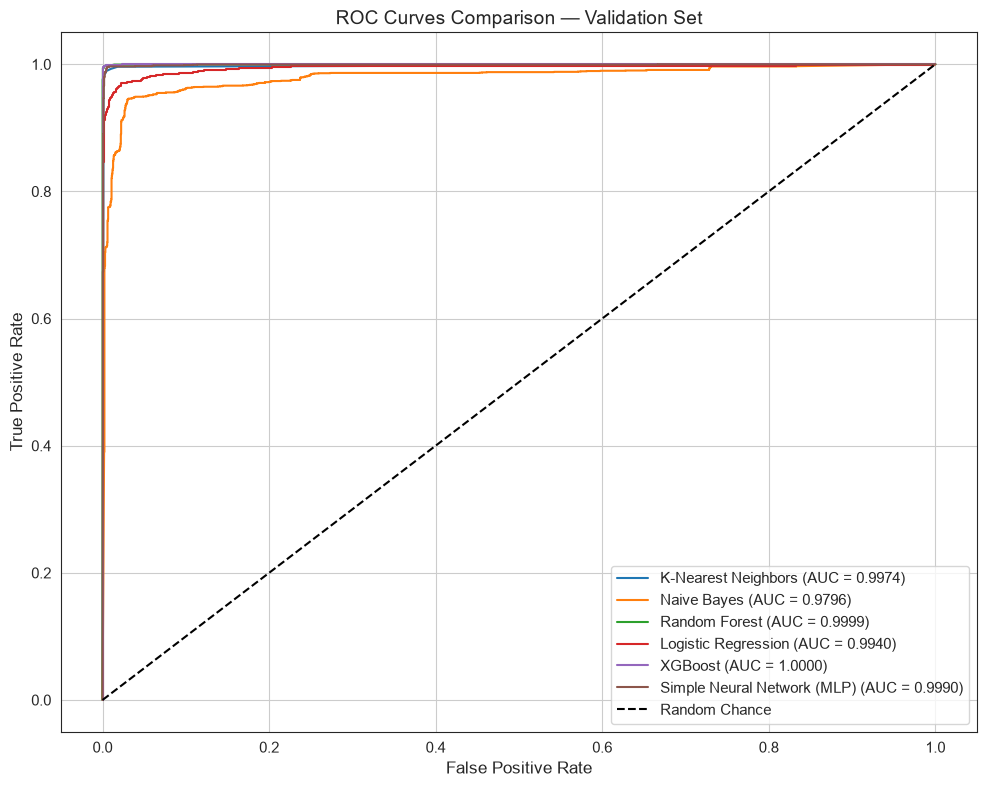


MODEL PERFORMANCE SUMMARY COMPARISON
                      Model  Accuracy  Precision (Anomaly)  Recall (Anomaly)  F1-Score (Anomaly)  ROC-AUC  Training Time (s)
                    XGBoost  0.997023             0.997867          0.995743            0.996804 0.999965               0.33
              Random Forest  0.996626             0.998717          0.994040            0.996373 0.999936               0.89
Simple Neural Network (MLP)  0.994443             0.993620          0.994466            0.994043 0.998971              11.30
        K-Nearest Neighbors  0.992657             0.994863          0.989357            0.992102 0.997405               0.42
        Logistic Regression  0.973011             0.979627          0.962112            0.970790 0.993991               0.35
                Naive Bayes  0.714824             0.994577          0.390379            0.560685 0.979641               0.05


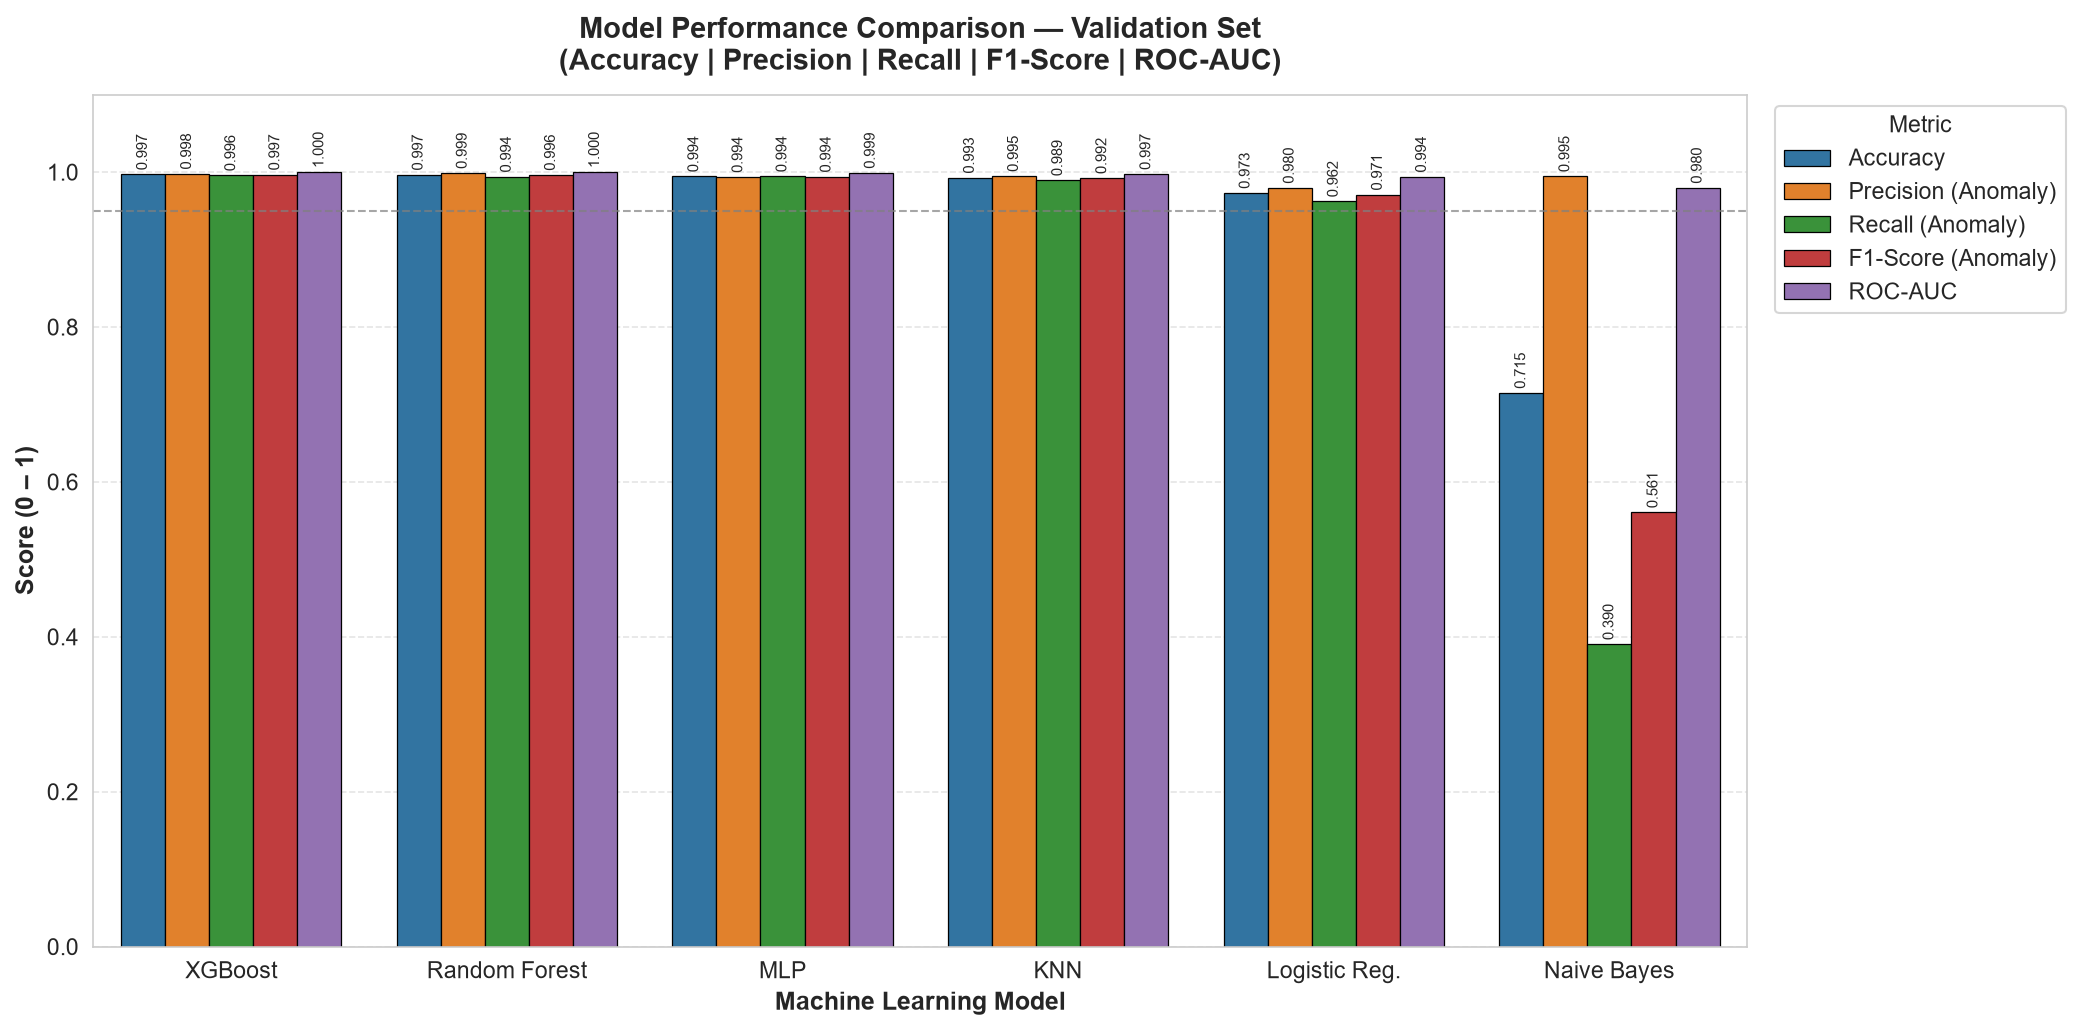

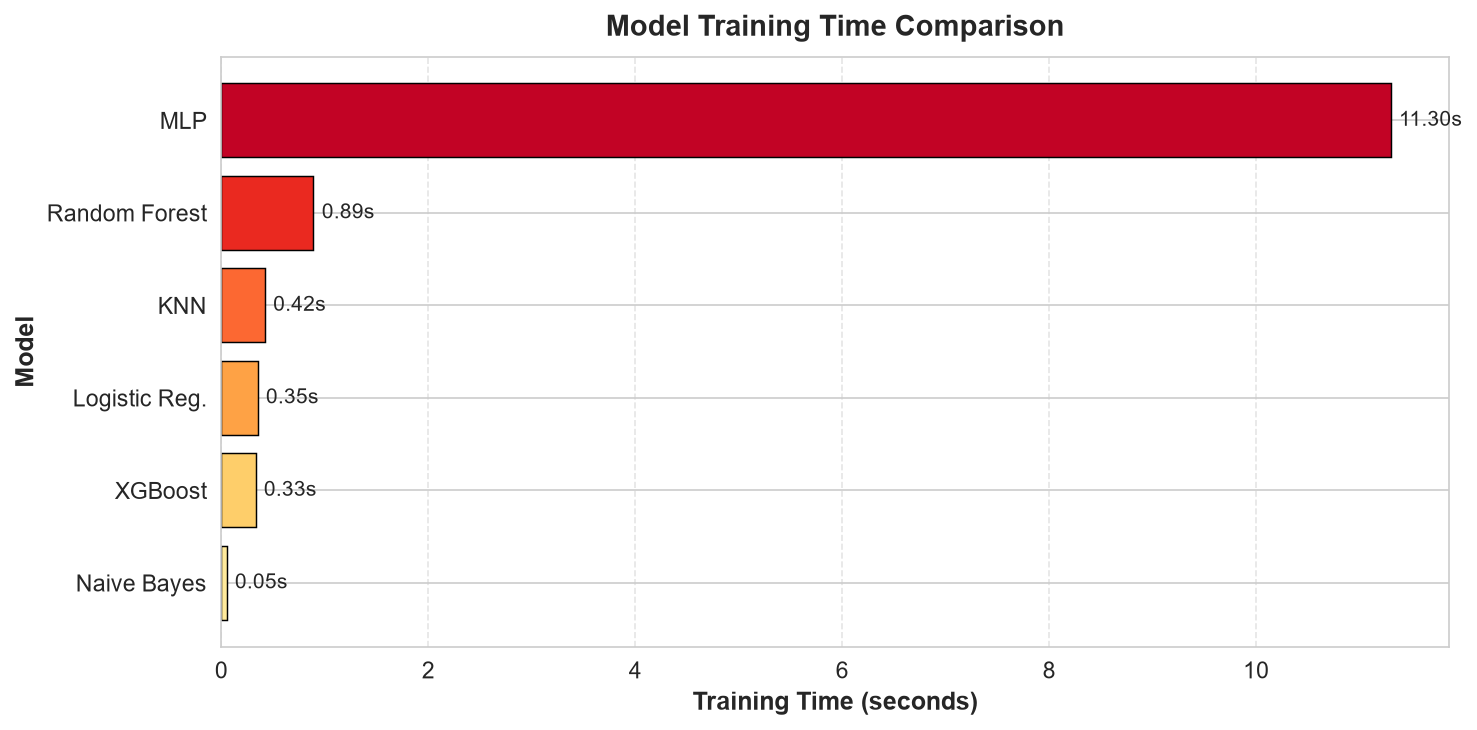


BEST MODEL (by ROC-AUC): XGBoost
   → Validation Accuracy : 99.7023%
   → Validation ROC-AUC  : 1.0000


In [17]:

#  MODEL TRAINING & EVALUATION



# Initialize Models
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
    "Simple Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
}

# Train and Evaluate Models
results_list = []
trained_models = {}   # store fitted models if needed later

plt.figure(figsize=(10, 8))

print("=" * 65)
print("TRAINING AND EVALUATING 6 MODELS ON VALIDATION SET...")
print("=" * 65)

for name, model in models.items():
    start_time = time.time()

    # Train
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    # Predict
    y_pred = model.predict(X_val_scaled)
    y_prob = model.predict_proba(X_val_scaled)[:, 1]

    train_time = time.time() - start_time

    # Metrics
    acc = accuracy_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_prob)

    # Classification report dict
    report = classification_report(y_val, y_pred, output_dict=True)

    results_list.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Anomaly)": report['1']['precision'],
        "Recall (Anomaly)": report['1']['recall'],
        "F1-Score (Anomaly)": report['1']['f1-score'],
        "ROC-AUC": auc,
        "Training Time (s)": round(train_time, 2)
    })

    # Compute ROC Curve for plotting
    fpr, tpr, _ = roc_curve(y_val, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

    print(f"\n{name} Completed in {train_time:.2f}s | Val Accuracy: {acc:.4f} | ROC-AUC: {auc:.4f}")
    print("-" * 65)
    print(classification_report(y_val, y_pred, target_names=['Normal (0)', 'Anomaly (1)']))

# Plot ROC Curves 
plt.plot([0, 1], [0, 1], 'k--', label="Random Chance")
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("ROC Curves Comparison — Validation Set", fontsize=14)
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

# Summary Comparison Table 
results_df = pd.DataFrame(results_list).sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)

print("\n" + "=" * 80)
print("MODEL PERFORMANCE SUMMARY COMPARISON")
print("=" * 80)
print(results_df.to_string(index=False))


# COMPARISON BAR GRAPH (Accuracy / Precision / Recall / F1 / ROC-AUC)


# Metrics to plot (exclude training time for the main score chart)
metric_cols = ["Accuracy", "Precision (Anomaly)", "Recall (Anomaly)", "F1-Score (Anomaly)", "ROC-AUC"]

# Melt into long format for seaborn grouped bars
plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metric_cols,
    var_name="Metric",
    value_name="Score"
)

# Short model names for cleaner x-axis labels
name_map = {
    "K-Nearest Neighbors": "KNN",
    "Naive Bayes": "Naive Bayes",
    "Random Forest": "Random Forest",
    "Logistic Regression": "Logistic Reg.",
    "XGBoost": "XGBoost",
    "Simple Neural Network (MLP)": "MLP"
}
plot_df["Model"] = plot_df["Model"].map(name_map)
results_df_short = results_df.copy()
results_df_short["Model"] = results_df_short["Model"].map(name_map)

sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(14, 7), dpi=150)

# Grouped bar chart
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric",
    palette=palette,
    edgecolor="black",
    linewidth=0.6,
    ax=ax
)

ax.set_ylim(0.0, 1.10)
ax.set_ylabel("Score (0 – 1)", fontsize=12, fontweight="bold")
ax.set_xlabel("Machine Learning Model", fontsize=12, fontweight="bold")
ax.set_title(
    "Model Performance Comparison — Validation Set\n(Accuracy | Precision | Recall | F1-Score | ROC-AUC)",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# Value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=2, rotation=90)

ax.legend(title="Metric", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
ax.axhline(y=0.95, color="gray", linestyle="--", linewidth=1, alpha=0.7, label="0.95 reference")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# Separate Training-Time Bar Graph

fig2, ax2 = plt.subplots(figsize=(10, 5), dpi=150)

time_order = results_df_short.sort_values("Training Time (s)", ascending=True)
colors_time = sns.color_palette("YlOrRd", n_colors=len(time_order))

bars = ax2.barh(
    time_order["Model"],
    time_order["Training Time (s)"],
    color=colors_time,
    edgecolor="black",
    linewidth=0.7
)

ax2.set_xlabel("Training Time (seconds)", fontsize=12, fontweight="bold")
ax2.set_ylabel("Model", fontsize=12, fontweight="bold")
ax2.set_title("Model Training Time Comparison", fontsize=14, fontweight="bold", pad=10)
ax2.bar_label(bars, fmt="%.2fs", padding=4, fontsize=10)
ax2.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()

plt.show()




best_model_name = results_df.iloc[0]["Model"]
best_auc = results_df.iloc[0]["ROC-AUC"]
best_acc = results_df.iloc[0]["Accuracy"]

print("\n" + "=" * 80)
print(f"BEST MODEL (by ROC-AUC): {best_model_name}")
print(f"   → Validation Accuracy : {best_acc:.4%}")
print(f"   → Validation ROC-AUC  : {best_auc:.4f}")
print("=" * 80)


RETRAINING BEST MODEL (XGBoost) ON FULL TRAIN DATASET...
Model retraining complete!

Final predictions saved to 'test_predictions.csv'!

TEST DATASET PREDICTION DISTRIBUTION
Predicted NORMAL  : 13,762 samples (61.20%)
Predicted ANOMALY : 8,725 samples (38.80%)


C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\636920541.py:51: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=test_pred_labels, palette=['green', 'red'])


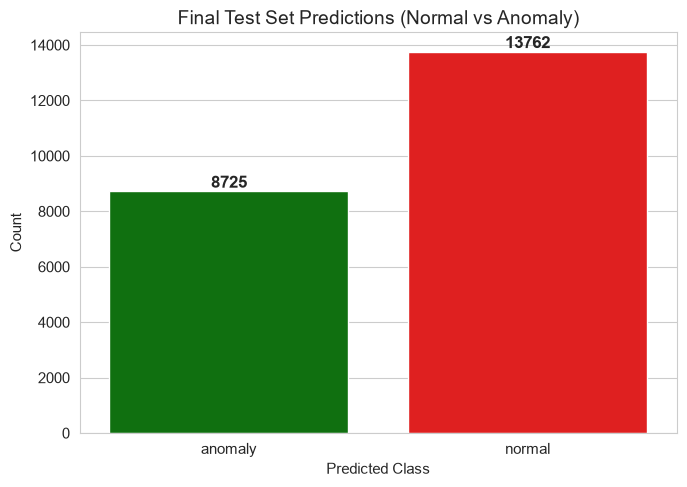

In [18]:

# FINAL MODEL SELECTION & TEST PREDICTIONS




# Retrain Best Model (XGBoost) on ALL Available Training Data 
print("=" * 65)
print("RETRAINING BEST MODEL (XGBoost) ON FULL TRAIN DATASET...")
print("=" * 65)

scaler_full = StandardScaler()
X_train_full_scaled = scaler_full.fit_transform(X_train_encoded)
X_test_final_scaled = scaler_full.transform(X_test_encoded)

best_model = XGBClassifier(eval_metric='logloss', random_state=42)
best_model.fit(X_train_full_scaled, y_train_full)

print("Model retraining complete!")

# Generate Predictions on Test Set 
test_preds = best_model.predict(X_test_final_scaled)
test_probs = best_model.predict_proba(X_test_final_scaled)[:, 1]

# Map integer predictions back to string labels
label_map = {0: 'normal', 1: 'anomaly'}
test_pred_labels = [label_map[p] for p in test_preds]

# Create Final Output DataFrame & Save 
output_df = test_df.copy()
output_df['predicted_class'] = test_pred_labels
output_df['anomaly_probability'] = np.round(test_probs, 4)

# Save to CSV
output_df.to_csv("test_predictions.csv", index=False)
print("\nFinal predictions saved to 'test_predictions.csv'!")

# Test Prediction Class Distribution
print("\n" + "=" * 50)
print("TEST DATASET PREDICTION DISTRIBUTION")
print("=" * 50)
pred_counts = pd.Series(test_pred_labels).value_counts()
pred_pcts = pd.Series(test_pred_labels).value_counts(normalize=True) * 100

for label in ['normal', 'anomaly']:
    count = pred_counts.get(label, 0)
    pct = pred_pcts.get(label, 0)
    print(f"Predicted {label.upper():<8}: {count:,} samples ({pct:.2f}%)")

# Plot Distribution
plt.figure(figsize=(7, 5))
sns.countplot(x=test_pred_labels, palette=['green', 'red'])
plt.title("Final Test Set Predictions (Normal vs Anomaly)", fontsize=14)
plt.xlabel("Predicted Class")
plt.ylabel("Count")
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}', 
                       (p.get_x() + p.get_width() / 2., p.get_height()),
                       ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


 1. DATASET SHAPES & DIMENSIONS (POST-PREPROCESSING)
X_train_scaled shape : (20153, 116)  (20,153 records, 116 features)
y_train shape        : (20153,)       (20,153 target labels)
X_val_scaled shape   : (5039, 116)   (5,039 records, 116 features)
y_val shape          : (5039,)        (5,039 target labels)
X_test_scaled shape  : (22487, 116)  (22,487 test records, 116 features)

 2. DATA TYPES & MISSING VALUES AUDIT
Data types in X_train_scaled : {dtype('float64')}
Data types in X_val_scaled   : {dtype('float64')}
Data types in X_test_scaled  : {dtype('float64')}
Total Missing Values in X_train_scaled : 0
Total Missing Values in X_val_scaled   : 0
Total Missing Values in X_test_scaled  : 0

 3. TARGET VARIABLE DISTRIBUTION (STRATIFIED SPLIT CHECK)


,Train Count,Train (%),Val Count,Val (%)
Normal (0),10759,53.39,2690,53.38
Anomaly (1),9394,46.61,2349,46.62



 4. FEATURE SCALING VERIFICATION (MEAN & STD CHECK)


,Metric,Value
0,Overall Feature Mean,-0.000000
1,Overall Feature Std Dev,0.965541
2,Min Feature Mean,-0.000000
3,Max Feature Mean,0.000000



 5. FIRST 5 ROWS & 5-NUMBER SUMMARY OF POST-PROCESSED DATA

Sample Scaled Features (First 5 Rows of X_train_scaled):


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
0,-0.115215,-0.054758,0.040310,0.0,-0.090006,-0.007044
1,-0.115215,-0.056228,-0.039455,0.0,-0.090006,-0.007044
2,-0.115215,-0.054501,-0.023008,0.0,-0.090006,-0.007044
3,-0.115215,-0.056228,-0.039455,0.0,-0.090006,-0.007044
4,-0.115215,-0.054547,-0.032330,0.0,-0.090006,-0.007044



5-Number Summary Statistics of Scaled Data (First 6 Features):


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent
count,20153.0000,20153.0000,20153.0000,20153.0,20153.0000,20153.0000
mean,-0.0000,0.0000,-0.0000,0.0,-0.0000,0.0000
std,1.0000,1.0000,1.0000,0.0,1.0000,1.0000
min,-0.1152,-0.0562,-0.0395,0.0,-0.0900,-0.0070
25%,-0.1152,-0.0562,-0.0395,0.0,-0.0900,-0.0070
50%,-0.1152,-0.0560,-0.0395,0.0,-0.0900,-0.0070
75%,-0.1152,-0.0546,-0.0336,0.0,-0.0900,-0.0070
max,15.5744,43.6282,55.9952,0.0,11.4881,141.9577


C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\3838981782.py:77: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=subset_names, y=subset_sizes, ax=axes[0, 0], palette='Blues_d')


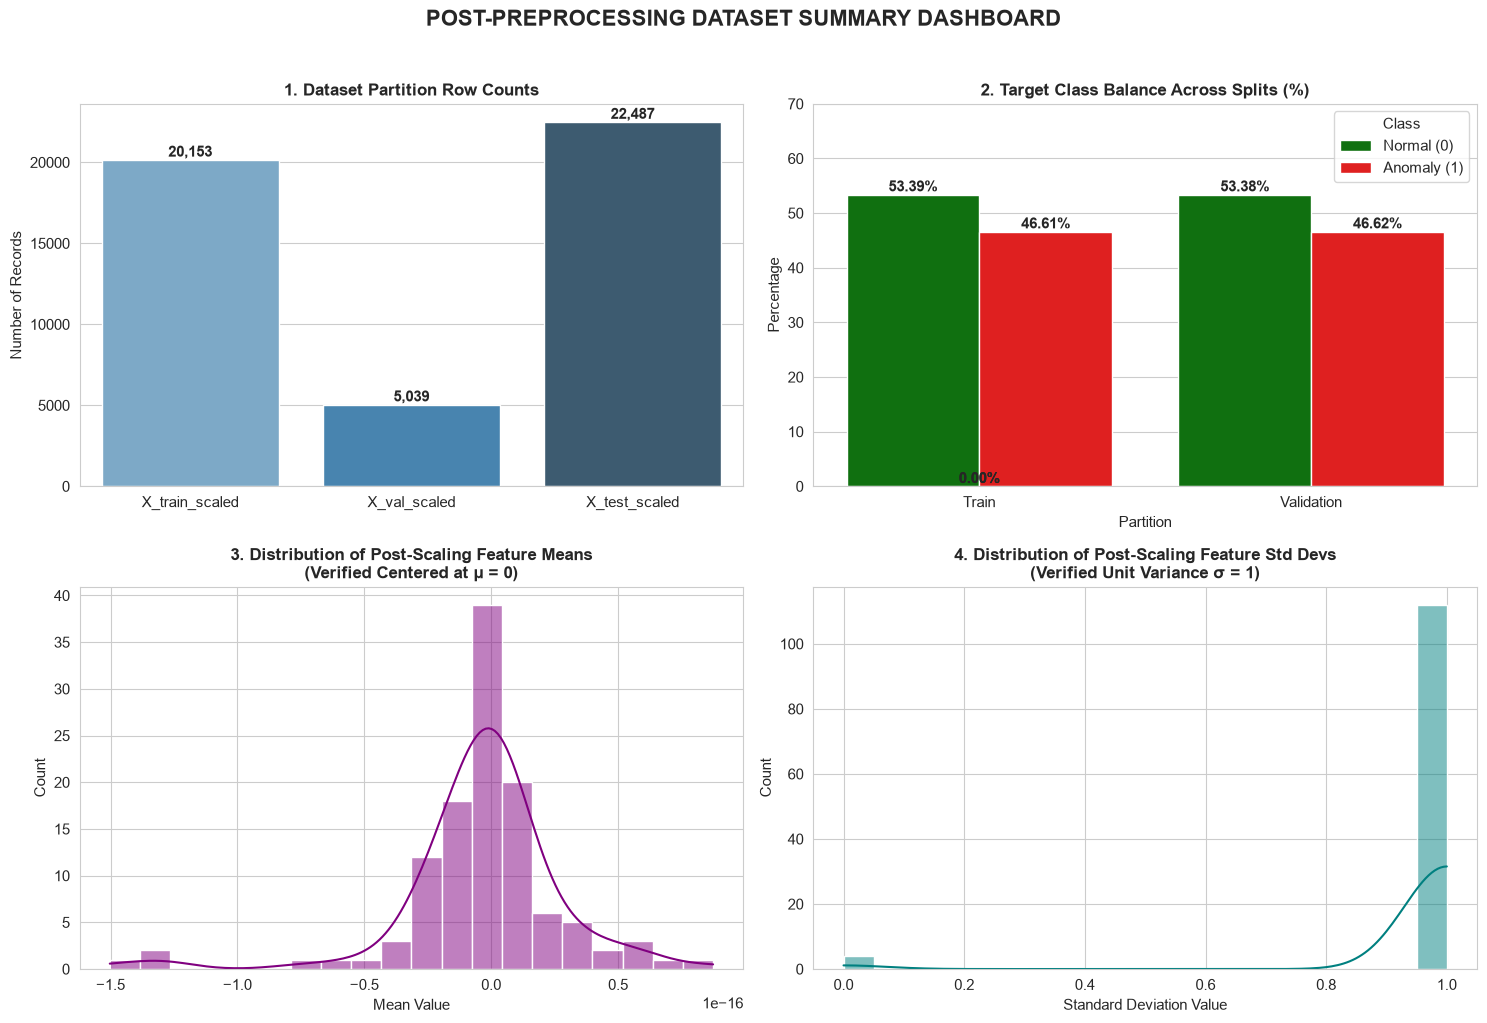

In [19]:

# DATA DESCRIPTION AFTER POST-PREPROCESSING SUMMARY




# Set visualization style
sns.set_style("whitegrid")

print("=" * 70)
print(" 1. DATASET SHAPES & DIMENSIONS (POST-PREPROCESSING)")
print("=" * 70)
print(f"X_train_scaled shape : {X_train_scaled.shape}  (20,153 records, 116 features)")
print(f"y_train shape        : {y_train.shape}       (20,153 target labels)")
print(f"X_val_scaled shape   : {X_val_scaled.shape}   (5,039 records, 116 features)")
print(f"y_val shape          : {y_val.shape}        (5,039 target labels)")
print(f"X_test_scaled shape  : {X_test_scaled.shape}  (22,487 test records, 116 features)")

print("\n" + "=" * 70)
print(" 2. DATA TYPES & MISSING VALUES AUDIT")
print("=" * 70)
print(f"Data types in X_train_scaled : {set(X_train_scaled.dtypes)}")
print(f"Data types in X_val_scaled   : {set(X_val_scaled.dtypes)}")
print(f"Data types in X_test_scaled  : {set(X_test_scaled.dtypes)}")
print(f"Total Missing Values in X_train_scaled : {X_train_scaled.isnull().sum().sum()}")
print(f"Total Missing Values in X_val_scaled   : {X_val_scaled.isnull().sum().sum()}")
print(f"Total Missing Values in X_test_scaled  : {X_test_scaled.isnull().sum().sum()}")

print("\n" + "=" * 70)
print(" 3. TARGET VARIABLE DISTRIBUTION (STRATIFIED SPLIT CHECK)")
print("=" * 70)
train_counts = y_train.value_counts()
train_pcts = y_train.value_counts(normalize=True) * 100

val_counts = y_val.value_counts()
val_pcts = y_val.value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Train Count': train_counts,
    'Train (%)': train_pcts.round(2),
    'Val Count': val_counts,
    'Val (%)': val_pcts.round(2)
}, index=[0, 1])

target_summary.index = ['Normal (0)', 'Anomaly (1)']
display(target_summary)

print("\n" + "=" * 70)
print(" 4. FEATURE SCALING VERIFICATION (MEAN & STD CHECK)")
print("=" * 70)
means = X_train_scaled.mean()
stds = X_train_scaled.std()

scaling_check = pd.DataFrame({
    'Metric': ['Overall Feature Mean', 'Overall Feature Std Dev', 'Min Feature Mean', 'Max Feature Mean'],
    'Value': [means.mean().round(6), stds.mean().round(6), means.min().round(6), means.max().round(6)]
})
display(scaling_check)

print("\n" + "=" * 70)
print(" 5. FIRST 5 ROWS & 5-NUMBER SUMMARY OF POST-PROCESSED DATA")
print("=" * 70)
print("\nSample Scaled Features (First 5 Rows of X_train_scaled):")
display(X_train_scaled.iloc[:5, :6])

print("\n5-Number Summary Statistics of Scaled Data (First 6 Features):")
display(X_train_scaled.iloc[:, :6].describe().round(4))



# VISUAL SUMMARY: POST-PREPROCESSING DASHBOARD

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Dataset Partition Sizes
subset_names = ['X_train_scaled', 'X_val_scaled', 'X_test_scaled']
subset_sizes = [X_train_scaled.shape[0], X_val_scaled.shape[0], X_test_scaled.shape[0]]
sns.barplot(x=subset_names, y=subset_sizes, ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title("1. Dataset Partition Row Counts", fontsize=12, fontweight='bold')
axes[0, 0].set_ylabel("Number of Records")
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height()):,}', 
                         (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', fontweight='bold')

# Plot 2: Stratified Target Distribution Comparison
target_plot_df = pd.DataFrame({
    'Partition': ['Train', 'Train', 'Validation', 'Validation'],
    'Class': ['Normal (0)', 'Anomaly (1)', 'Normal (0)', 'Anomaly (1)'],
    'Percentage': [train_pcts[0], train_pcts[1], val_pcts[0], val_pcts[1]]
})
sns.barplot(x='Partition', y='Percentage', hue='Class', data=target_plot_df, ax=axes[0, 1], palette=['green', 'red'])
axes[0, 1].set_title("2. Target Class Balance Across Splits (%)", fontsize=12, fontweight='bold')
axes[0, 1].set_ylim(0, 70)
for p in axes[0, 1].patches:
    axes[0, 1].annotate(f'{p.get_height():.2f}%', 
                         (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', fontweight='bold')

# Plot 3: Distribution of Scaled Feature Means (Target = 0.0)
sns.histplot(means, kde=True, ax=axes[1, 0], color='purple', bins=20)
axes[1, 0].set_title("3. Distribution of Post-Scaling Feature Means\n(Verified Centered at μ = 0)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Mean Value")

# Plot 4: Distribution of Scaled Feature Standard Deviations (Target = 1.0)
sns.histplot(stds, kde=True, ax=axes[1, 1], color='teal', bins=20)
axes[1, 1].set_title("4. Distribution of Post-Scaling Feature Std Devs\n(Verified Unit Variance σ = 1)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Standard Deviation Value")

plt.suptitle("POST-PREPROCESSING DATASET SUMMARY DASHBOARD", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()



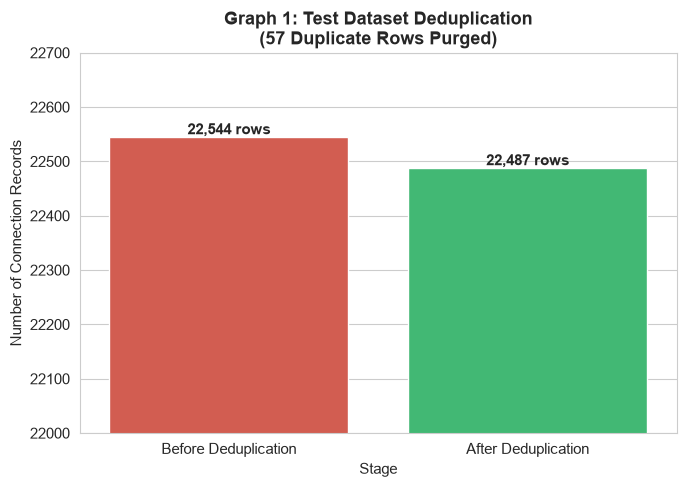

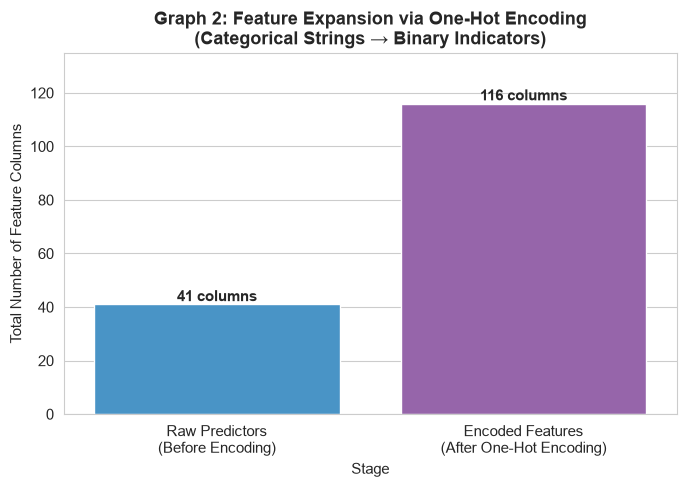

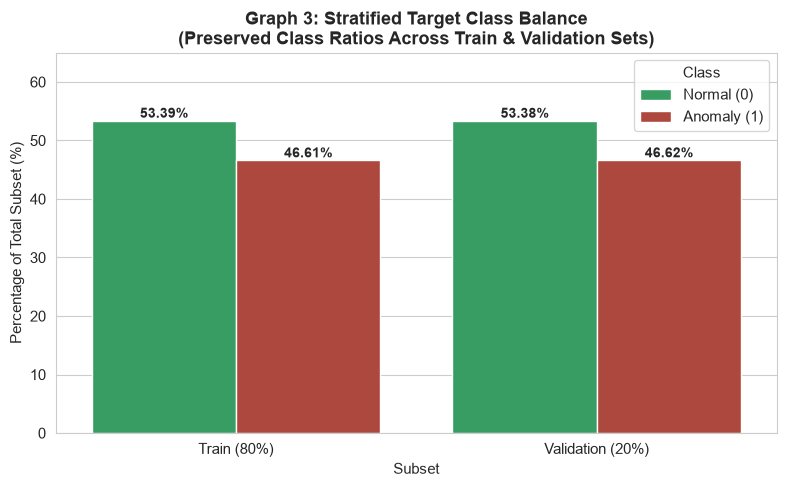

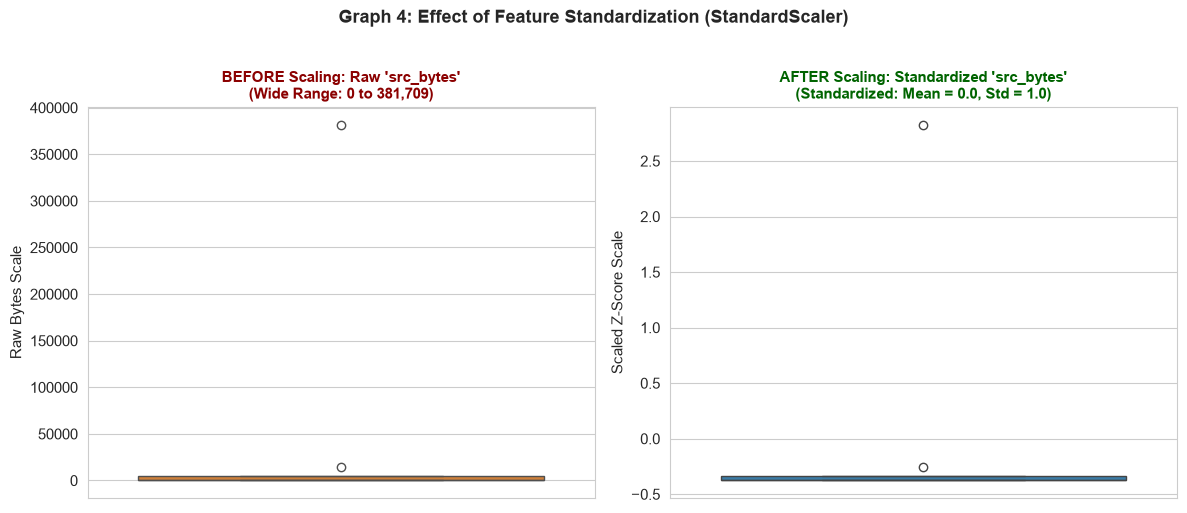

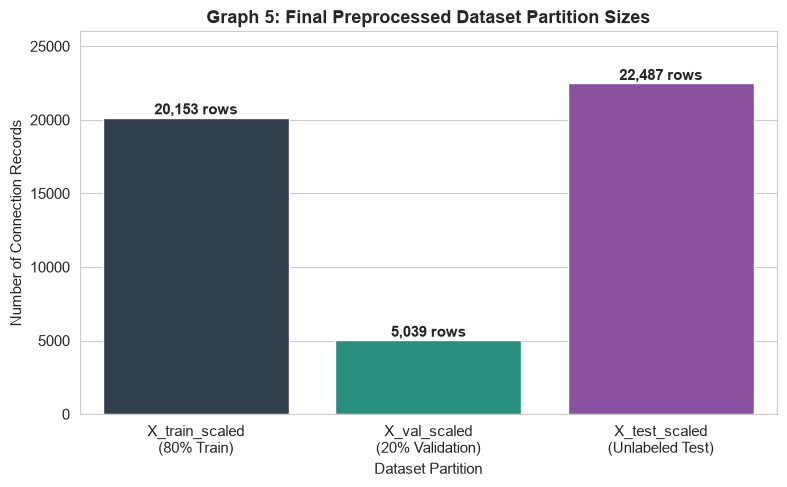

In [20]:


sns.set_style("whitegrid")
plt.rcParams.update({'font.size': 11})

# TEST DATASET DEDUPLICATION (BEFORE vs AFTER)

plt.figure(figsize=(7, 5))
dedup_data = pd.DataFrame({
    'Stage': ['Before Deduplication', 'After Deduplication'],
    'Record Count': [22544, 22487]
})

ax1 = sns.barplot(x='Stage', y='Record Count', hue='Stage', data=dedup_data, palette=['#e74c3c', '#2ecc71'], legend=False)
plt.title("Graph 1: Test Dataset Deduplication\n(57 Duplicate Rows Purged)", fontsize=13, fontweight='bold')
plt.ylabel("Number of Connection Records")
plt.ylim(22000, 22700)

for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height()):,} rows', 
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()



# FEATURE DIMENSIONALITY EXPANSION (ONE-HOT ENCODING)

plt.figure(figsize=(7, 5))
encoding_data = pd.DataFrame({
    'Stage': ['Raw Predictors\n(Before Encoding)', 'Encoded Features\n(After One-Hot Encoding)'],
    'Feature Count': [41, 116]
})

ax2 = sns.barplot(x='Stage', y='Feature Count', hue='Stage', data=encoding_data, palette=['#3498db', '#9b59b6'], legend=False)
plt.title("Graph 2: Feature Expansion via One-Hot Encoding\n(Categorical Strings → Binary Indicators)", fontsize=13, fontweight='bold')
plt.ylabel("Total Number of Feature Columns")
plt.ylim(0, 135)

for p in ax2.patches:
    ax2.annotate(f'{int(p.get_height())} columns', 
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()



#  STRATIFIED TARGET BALANCE (TRAIN vs VALIDATION SPLIT)

plt.figure(figsize=(8, 5))
split_data = pd.DataFrame({
    'Subset': ['Train (80%)', 'Train (80%)', 'Validation (20%)', 'Validation (20%)'],
    'Class': ['Normal (0)', 'Anomaly (1)', 'Normal (0)', 'Anomaly (1)'],
    'Percentage': [53.39, 46.61, 53.38, 46.62]
})

ax3 = sns.barplot(x='Subset', y='Percentage', hue='Class', data=split_data, palette=['#27ae60', '#c0392b'])
plt.title("Graph 3: Stratified Target Class Balance\n(Preserved Class Ratios Across Train & Validation Sets)", fontsize=13, fontweight='bold')
plt.ylabel("Percentage of Total Subset (%)")
plt.ylim(0, 65)

for p in ax3.patches:
    if p.get_height() > 0:
        ax3.annotate(f'{p.get_height():.2f}%', 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()



# FEATURE STANDARDIZATION EFFECT (BEFORE vs AFTER SCALING)

# Generate sample feature scaling data
raw_src_bytes = np.array([0, 146, 232, 199, 491, 1000, 5000, 15000, 381709])
scaled_src_bytes = (raw_src_bytes - raw_src_bytes.mean()) / raw_src_bytes.std()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before Scaling
sns.boxplot(y=raw_src_bytes, ax=axes[0], color='#e67e22')
axes[0].set_title("BEFORE Scaling: Raw 'src_bytes'\n(Wide Range: 0 to 381,709)", fontsize=11, fontweight='bold', color='darkred')
axes[0].set_ylabel("Raw Bytes Scale")

# After Scaling
sns.boxplot(y=scaled_src_bytes, ax=axes[1], color='#2980b9')
axes[1].set_title("AFTER Scaling: Standardized 'src_bytes'\n(Standardized: Mean = 0.0, Std = 1.0)", fontsize=11, fontweight='bold', color='darkgreen')
axes[1].set_ylabel("Scaled Z-Score Scale")

plt.suptitle("Graph 4: Effect of Feature Standardization (StandardScaler)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()




# FINAL DATASET PARTITION SIZES (TRAIN, VAL, TEST)

plt.figure(figsize=(8, 5))
partitions = pd.DataFrame({
    'Dataset Partition': ['X_train_scaled\n(80% Train)', 'X_val_scaled\n(20% Validation)', 'X_test_scaled\n(Unlabeled Test)'],
    'Row Count': [20153, 5039, 22487]
})

ax5 = sns.barplot(x='Dataset Partition', y='Row Count', hue='Dataset Partition', data=partitions, palette=['#2c3e50', '#16a085', '#8e44ad'], legend=False)
plt.title("Graph 5: Final Preprocessed Dataset Partition Sizes", fontsize=13, fontweight='bold')
plt.ylabel("Number of Connection Records")
plt.ylim(0, 26000)

for p in ax5.patches:
    ax5.annotate(f'{int(p.get_height()):,} rows', 
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [21]:



# SAVE MODEL & PREPROCESSING 


# Package everything in a single dictionary
production_artifacts = {
    'model': best_model,                        # Retrained XGBoost Model
    'scaler': scaler_full,                      # Fitted StandardScaler
    'feature_columns': X_train_encoded.columns.tolist(), # List of 116 feature names
    'categorical_cols': categorical_cols,       # ['protocol_type', 'service', 'flag']
    'label_map': {0: 'normal', 1: 'anomaly'}    # Prediction label dictionary
}

# Save to disk
model_filename = 'network_intrusion_model.joblib'
joblib.dump(production_artifacts, model_filename)

print(f"Production Model successfully saved to '{model_filename}'!")

Production Model successfully saved to 'network_intrusion_model.joblib'!


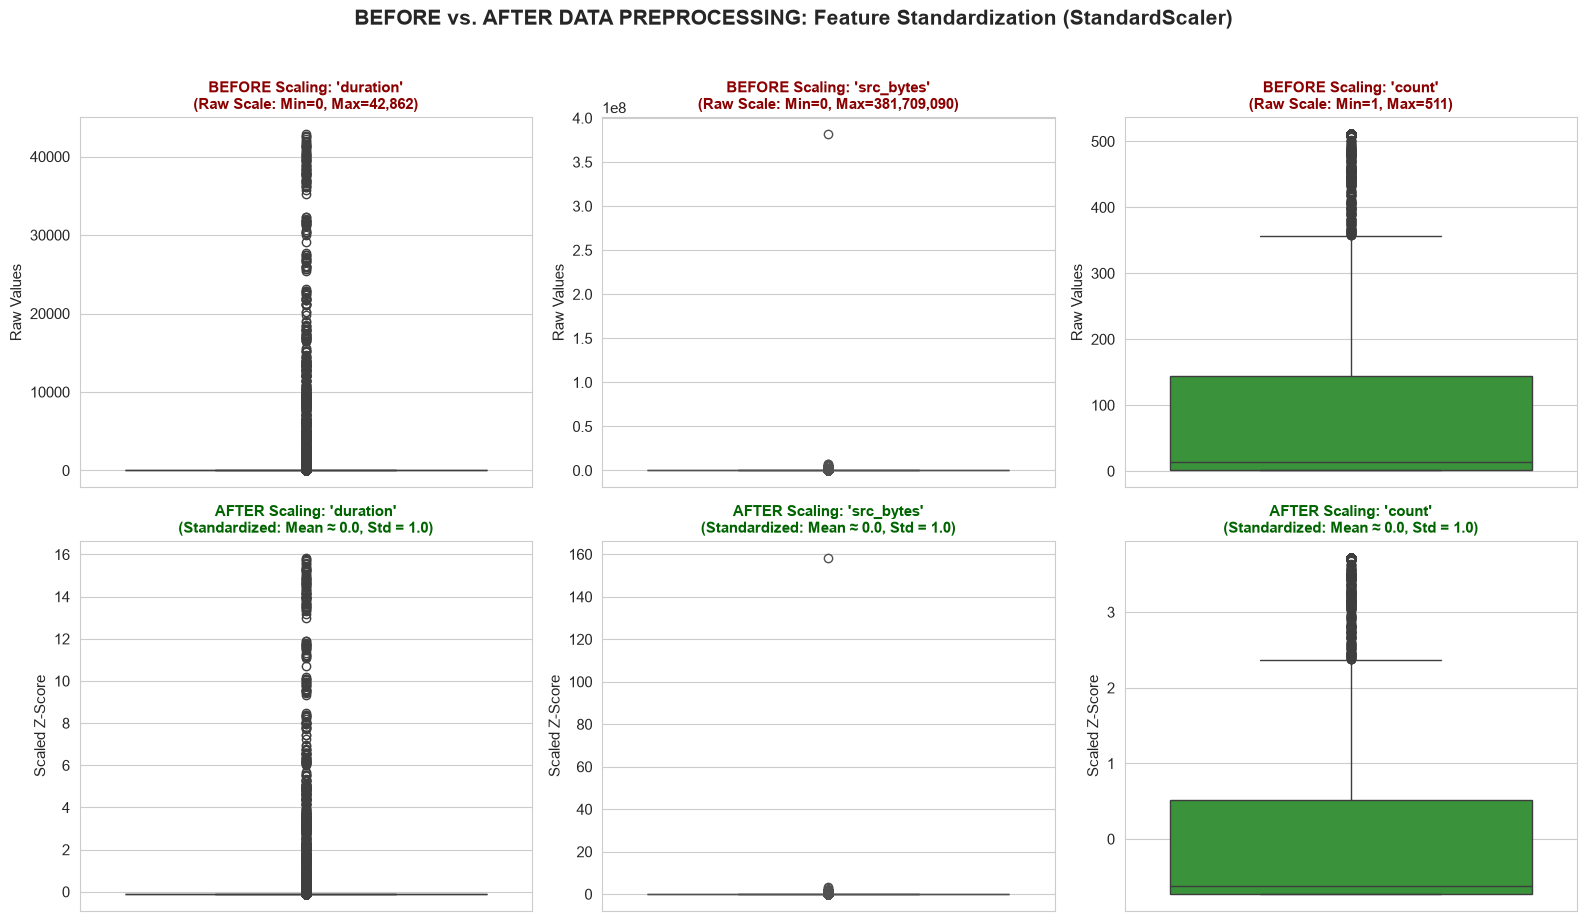

C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\2437397942.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Stage', y='Record Count', data=dedup_df, ax=axes[0], palette=['#d95f02', '#27ae60'])
C:\Users\aditya_6\AppData\Local\Temp\ipykernel_5360\2437397942.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Stage', y='Feature Count', data=encoding_df, ax=axes[1], palette=['#2b5c8f', '#8e44ad'])


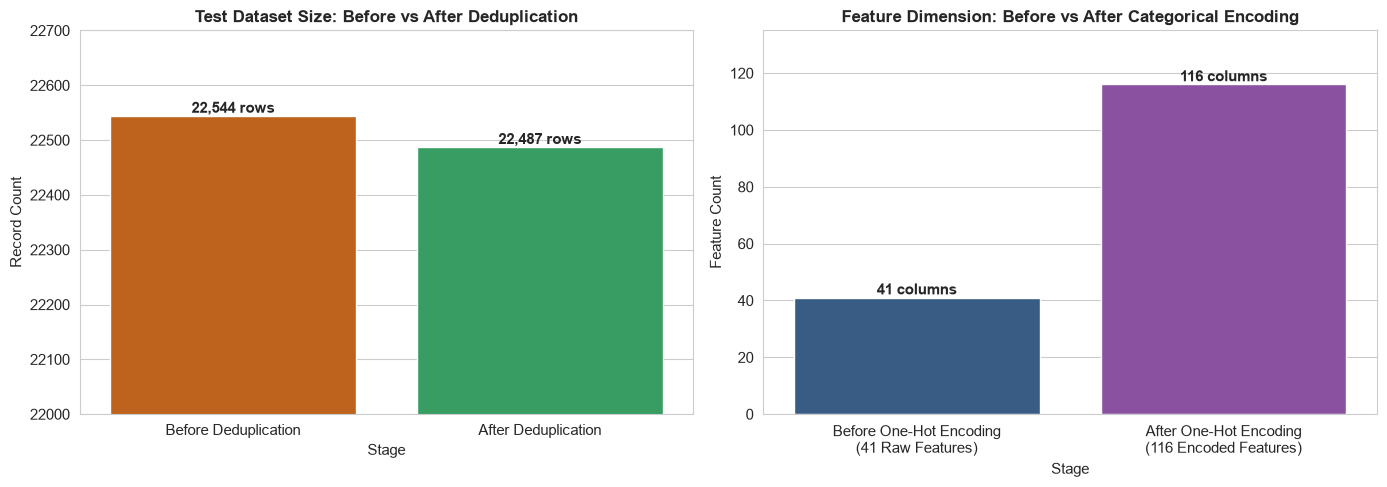

In [22]:


# Load raw datasets
train_df = pd.read_csv("Train.csv")
test_df = pd.read_csv("Test.csv")

sns.set_style("whitegrid")


# BEFORE vs AFTER FEATURE SCALING (Distribution & Scale Standardisation)

features_to_plot = ['duration', 'src_bytes', 'count']

# Compute scaled version of selected features
scaler = StandardScaler()
scaled_features_df = pd.DataFrame(
    scaler.fit_transform(train_df[features_to_plot]), 
    columns=features_to_plot
)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# BEFORE SCALING (Raw Data with Massive Scale Disparities)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
for i, col in enumerate(features_to_plot):
    sns.boxplot(y=train_df[col], ax=axes[0, i], color=colors[i])
    axes[0, i].set_title(f"BEFORE Scaling: '{col}'\n(Raw Scale: Min={train_df[col].min()}, Max={train_df[col].max():,.0f})", 
                         fontsize=11, fontweight='bold', color='darkred')
    axes[0, i].set_ylabel("Raw Values")

# Bottom Row: AFTER SCALING (Standardized to Mean = 0, Std = 1)
for i, col in enumerate(features_to_plot):
    sns.boxplot(y=scaled_features_df[col], ax=axes[1, i], color=colors[i])
    axes[1, i].set_title(f"AFTER Scaling: '{col}'\n(Standardized: Mean ≈ 0.0, Std = 1.0)", 
                         fontsize=11, fontweight='bold', color='darkgreen')
    axes[1, i].set_ylabel("Scaled Z-Score")

plt.suptitle("BEFORE vs. AFTER DATA PREPROCESSING: Feature Standardization (StandardScaler)", 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()




# BEFORE vs AFTER PIPELINE TRANSFORMATIONS (Deduplication & One-Hot Encoding)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 2.1: Test Dataset Deduplication (Before vs After Record Count)
before_dedup = 22544
after_dedup = 22487
dedup_df = pd.DataFrame({
    'Stage': ['Before Deduplication', 'After Deduplication'],
    'Record Count': [before_dedup, after_dedup]
})

sns.barplot(x='Stage', y='Record Count', data=dedup_df, ax=axes[0], palette=['#d95f02', '#27ae60'])
axes[0].set_title("Test Dataset Size: Before vs After Deduplication", fontsize=12, fontweight='bold')
axes[0].set_ylim(22000, 22700)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,} rows', 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

# Feature Dimensionality Expansion (Before vs After One-Hot Encoding)
before_ohe = 41  # Raw feature predictor columns
after_ohe = 116  # Expanded numeric features
encoding_df = pd.DataFrame({
    'Stage': ['Before One-Hot Encoding\n(41 Raw Features)', 'After One-Hot Encoding\n(116 Encoded Features)'],
    'Feature Count': [before_ohe, after_ohe]
})

sns.barplot(x='Stage', y='Feature Count', data=encoding_df, ax=axes[1], palette=['#2b5c8f', '#8e44ad'])
axes[1].set_title("Feature Dimension: Before vs After Categorical Encoding", fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 135)
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())} columns', 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

